In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [3]:
category_counts = (
    df["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="listing_count")
)
category_counts["listing_share_pct"] = category_counts["listing_count"] / len(df) * 100

display(category_counts.head(10))

top5_categories = category_counts.head(5).copy()
display(top5_categories)

,category,listing_count,listing_share_pct
0,Sports & Outdoors,836265,34.221949
1,Beauty,19312,0.790293
2,"Handmade Clothing, Shoes & Accessories",19229,0.786896
3,Bath & Body,19092,0.781290
4,Birthday Gifts,18978,0.776625
5,Manicure & Pedicure Products,18940,0.775070
6,Skin Care,18769,0.768072
7,Make-up,18756,0.767540
8,Hair Care,18735,0.766681
9,Fragrances,18564,0.759683


,category,listing_count,listing_share_pct
0,Sports & Outdoors,836265,34.221949
1,Beauty,19312,0.790293
2,"Handmade Clothing, Shoes & Accessories",19229,0.786896
3,Bath & Body,19092,0.781290
4,Birthday Gifts,18978,0.776625


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

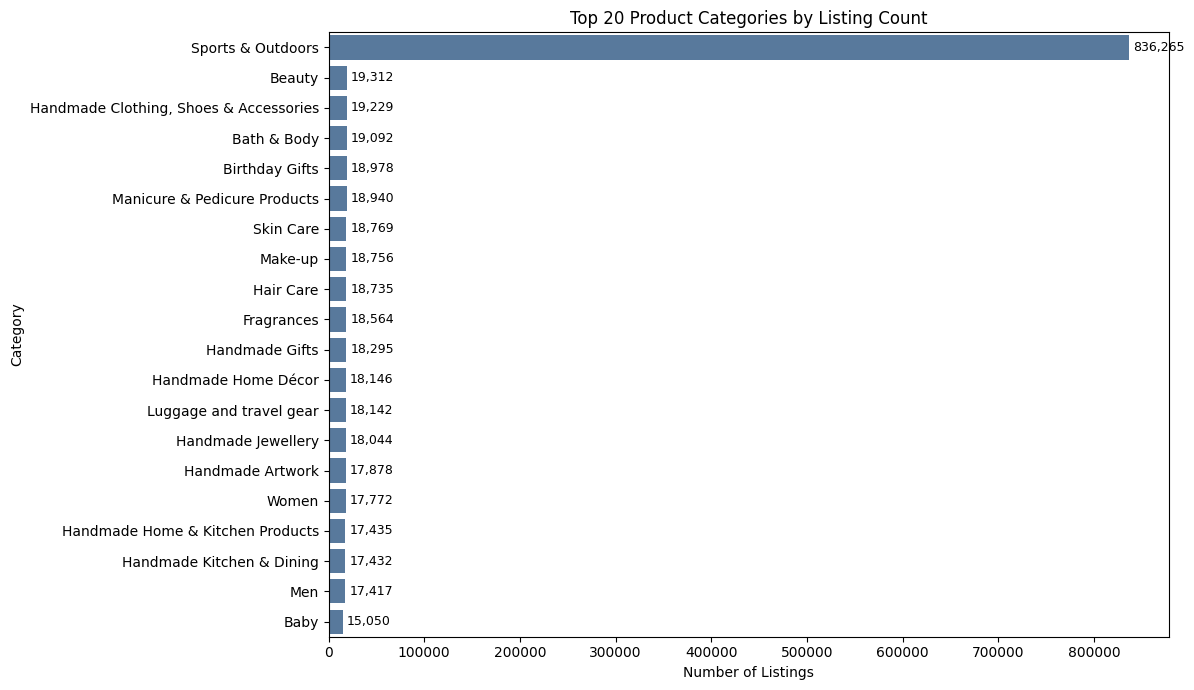

In [4]:
top20_categories = category_counts.head(20)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=top20_categories,
    x="listing_count",
    y="category",
    ax=ax,
    color="#4c78a8"
)
ax.set_title("Top 20 Product Categories by Listing Count")
ax.set_xlabel("Number of Listings")
ax.set_ylabel("Category")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, fontsize=9)
plt.tight_layout()
plt.show()

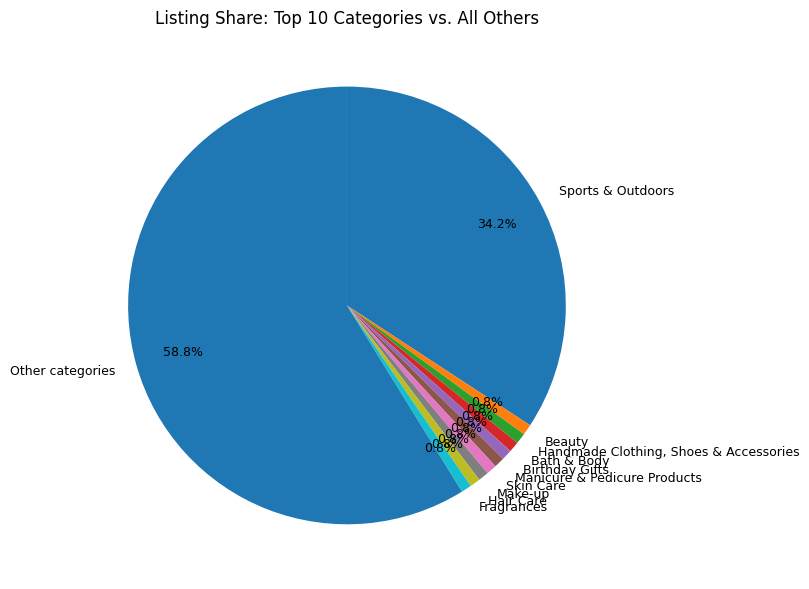

In [5]:
top10 = category_counts.head(10).copy()
other_count = category_counts.iloc[10:]["listing_count"].sum()
pie_data = pd.concat([
    top10[["category", "listing_count"]],
    pd.DataFrame({"category": ["Other categories"], "listing_count": [other_count]})
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    pie_data["listing_count"],
    labels=pie_data["category"],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    textprops={"fontsize": 9}
)
ax.set_title("Listing Share: Top 10 Categories vs. All Others")
plt.tight_layout()
plt.show()

The top 5 most listed categories are Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body, and Birthday Gifts.

Sports & Outdoors clearly dominates the listings with 836,265 products, representing 34.22% of all listings. The top 5 categories together represent 37.36% of the dataset.

From a business perspective, Amazon UK has a very large listing concentration in the leading category. That suggests intense competition there, while the smaller categories may offer more focused positioning opportunities.

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [6]:
price = df["price"].dropna()
price_q1 = price.quantile(0.25)
price_q3 = price.quantile(0.75)
price_iqr = price_q3 - price_q1
price_upper_fence = price_q3 + 1.5 * price_iqr
price_outlier_count = (price > price_upper_fence).sum()

price_stats = pd.DataFrame({
    "metric": [
        "mean", "median", "mode", "variance", "standard_deviation",
        "minimum", "q1", "q3", "maximum", "range", "interquartile_range",
        "upper_outlier_fence", "outlier_count", "outlier_share_pct"
    ],
    "value": [
        price.mean(), price.median(), price.mode().iloc[0], price.var(), price.std(),
        price.min(), price_q1, price_q3, price.max(), price.max() - price.min(), price_iqr,
        price_upper_fence, price_outlier_count, price_outlier_count / len(price) * 100
    ]
})

display(price_stats)
display(price.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]).to_frame("price"))

,metric,value
0,mean,89.243809
1,median,19.090000
2,mode,9.990000
3,variance,119445.485323
4,standard_deviation,345.608862
5,minimum,0.000000
6,q1,9.990000
7,q3,45.990000
8,maximum,100000.000000
9,range,100000.000000


,price
0.100,5.99
0.250,9.99
0.500,19.09
0.750,45.99
0.900,149.99
0.950,349.50
0.990,1408.82
0.999,4404.99


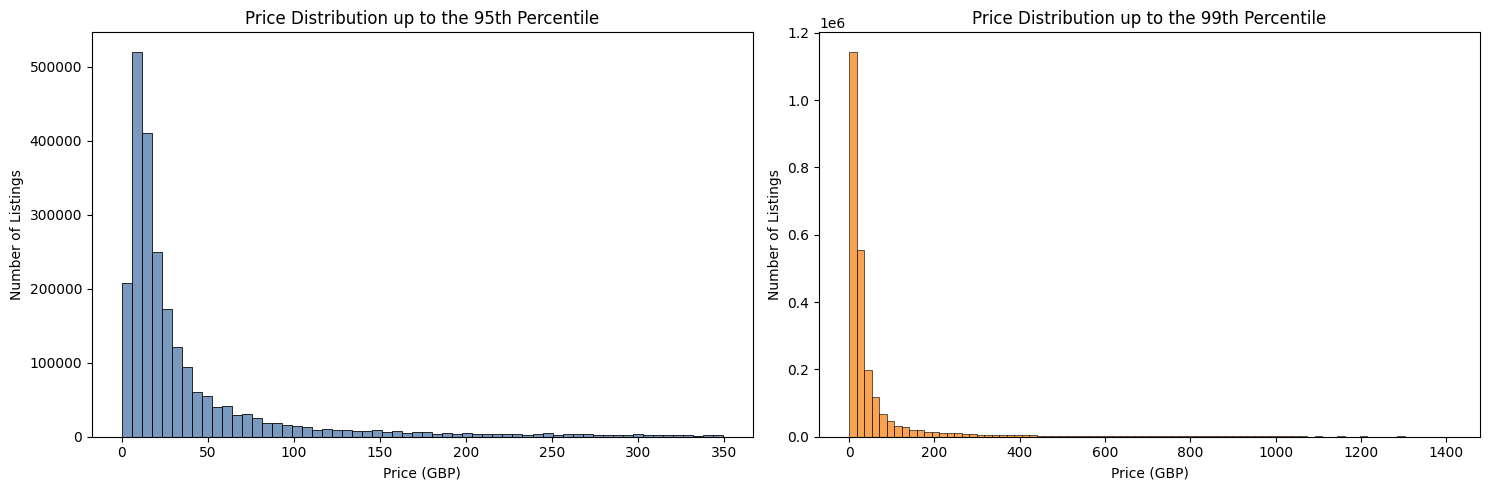

In [7]:
price_95 = price.quantile(0.95)
price_99 = price.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(price[price <= price_95], bins=60, ax=axes[0], color="#4c78a8")
axes[0].set_title("Price Distribution up to the 95th Percentile")
axes[0].set_xlabel("Price (GBP)")
axes[0].set_ylabel("Number of Listings")

sns.histplot(price[price <= price_99], bins=80, ax=axes[1], color="#f58518")
axes[1].set_title("Price Distribution up to the 99th Percentile")
axes[1].set_xlabel("Price (GBP)")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

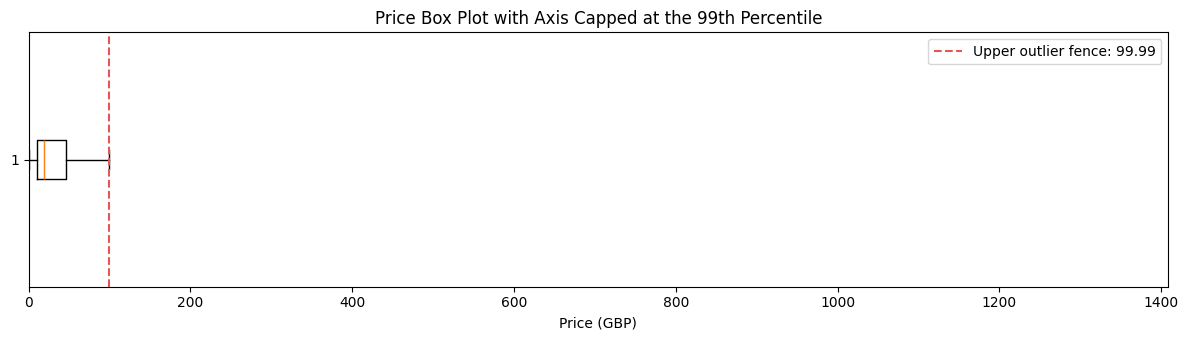

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.boxplot(price, vert=False, showfliers=False)
ax.axvline(price_upper_fence, color="#e45756", linestyle="--", label=f"Upper outlier fence: {price_upper_fence:,.2f}")
ax.set_xlim(0, price_99)
ax.set_title("Price Box Plot with Axis Capped at the 99th Percentile")
ax.set_xlabel("Price (GBP)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

The average product price is GBP 89.24, while the median is GBP 19.09 and the most common price point is GBP 9.99.

The mean is much higher than both the median and mode, which means the pricing distribution is strongly pulled upward by expensive products. Most listings are comparatively low-priced: 75% of products are at or below GBP 45.99, and 95% are at or below GBP 349.50.

Price dispersion is substantial. The range is GBP 100,000.00, the standard deviation is GBP 345.61, and the IQR is GBP 36.00. Using the 1.5 x IQR rule, prices above GBP 99.99 are potential outliers; this applies to 327,688 listings (13.41% of products).

The full histogram is hard to read because a small number of very expensive listings stretch the x-axis. Capping the chart at high percentiles or using a log-scaled price axis makes the main pricing pattern easier to interpret.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [10]:
rating = df["stars"].dropna()
rated = rating[rating > 0]

def rating_summary(series, label):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    return {
        "group": label,
        "count": len(series),
        "mean": series.mean(),
        "median": series.median(),
        "mode": series.mode().iloc[0],
        "variance": series.var(),
        "standard_deviation": series.std(),
        "q1": q1,
        "q3": q3,
        "interquartile_range": q3 - q1,
        "skewness": series.skew(),
        "kurtosis": series.kurtosis()
    }

rating_stats = pd.DataFrame([
    rating_summary(rating, "all products"),
    rating_summary(rated, "rated products only")
])

display(rating_stats)

zero_rating_count = (rating == 0).sum()
display(pd.DataFrame({
    "metric": ["zero_rating_count", "zero_rating_share_pct", "rated_product_count", "rated_product_share_pct"],
    "value": [zero_rating_count, zero_rating_count / len(rating) * 100, len(rated), len(rated) / len(rating) * 100]
}))

,group,count,mean,median,mode,variance,standard_deviation,q1,q3,interquartile_range,skewness,kurtosis
0,all products,2443651,2.152836,0.0,0.0,4.817434,2.194865,0.0,4.4,4.4,0.081207,-1.926006
1,rated products only,1218010,4.319161,4.4,4.5,0.308343,0.555287,4.1,4.6,0.5,-2.379568,9.781938


,metric,value
0,zero_rating_count,1.225641e+06
1,zero_rating_share_pct,5.015614e+01
2,rated_product_count,1.218010e+06
3,rated_product_share_pct,4.984386e+01


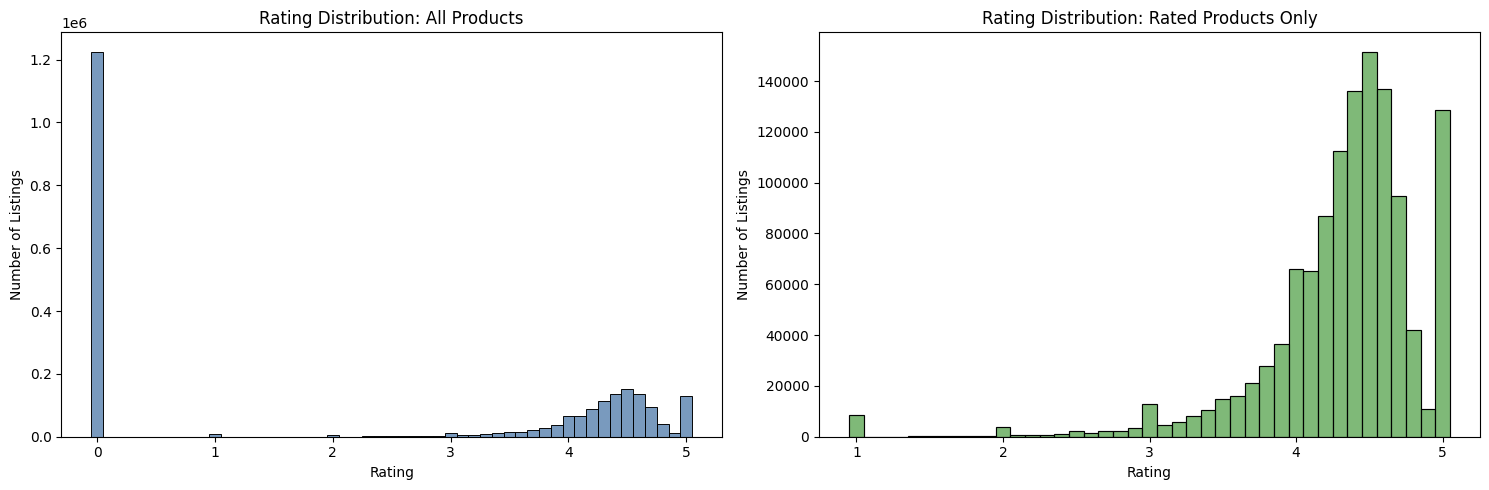

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(rating, bins=np.arange(-0.05, 5.15, 0.10), ax=axes[0], color="#4c78a8")
axes[0].set_title("Rating Distribution: All Products")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of Listings")

sns.histplot(rated, bins=np.arange(0.95, 5.15, 0.10), ax=axes[1], color="#54a24b")
axes[1].set_title("Rating Distribution: Rated Products Only")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

Using all products, the mean rating is 2.15, the median is 0.0, and the mode is 0.0. This raw result is heavily affected by the 1,225,641 listings (50.16%) with a rating of zero.

For products that have a positive rating, customers generally rate items highly: the mean is 4.32, the median is 4.4, and the mode is 4.5. The IQR is only 0.5, so most rated products cluster tightly in the high-rating range.

The raw rating distribution is not normal because it has a large spike at zero and another concentration around high ratings. Among rated products only, the distribution leans strongly toward higher ratings, with negative skewness of -2.38 and kurtosis of 9.78. The most common rating among rated products is 4.5.